## Self-Attention
### What if we replaced the recurrent layer with an attention mechanism?
**这就是瓦什瓦尼等人的著名论文《Attention Is All You Need》提出的核心观点。该论文推出了基于自注意力机制的Transformer架构，这一架构很快就在自然语言处理领域占据了绝对主导地位。**

### 编码器中的循环层接收源序列，并逐个生成隐藏状态。但我们不必采用这种方式生成隐藏状态。我们可以使用另一种独立的注意力机制来替代编码器。

+ 这些独立的注意力机制被称为自注意力机制，因为它们所有的输入——“键”、“值”以及“查询”——都来自编码器或解码器内部。
+ 前面介绍的注意力机制中，“键”和“值”来自编码器，而“查询”来自解码器，这类机制此后将被称为交叉注意力。
+ 我们作用于“键”、“查询”和“值”的仿射变换，同样可用于将维度从输入维度数量转换为隐藏维度数量（该变换此前由循环层完成）。

下图展示了一个使用自注意力机制的编码器：源序列（红色部分）同时充当“键”（K）、“值”（V）以及“查询”（Q）。
在编码器中，每个数据点都是一个“查询”（从侧面输入自注意力机制的红色箭头），因此会利用源序列中所有数据点（包括自身）的对齐向量，生成属于自己的上下文向量。这意味着一个数据点有可能生成**仅关注自身**的上下文向量。

![](../pictures/selfatten01.png)

我们先看左侧的自注意力机制，它用于生成源序列中第一个数据点$(x_{00}, x_{01})$对应的“隐藏状态”$(h_{00}, h_{01})$，下面详细了解其工作原理：
- 将第一个数据点经过变换后的坐标作为“查询向量”（Q）。
- 该“查询向量”（Q）会分别与两个“键向量”（K）进行配对计算：其中一个键向量是同一组坐标$(x_{00}, x_{01})$经过另一种变换得到，另一个则是第二个数据点$(x_{10}, x_{11})$变换后的结果。
- 上述配对计算会得到两个注意力分数（$\alpha$，即$s_0$和$s_1$），将这两个分数分别乘以对应的“值向量”（V）后求和，即可得到上下文向量：

![](../pictures/selfatten02.png)

- 接下来，上下文向量经过前馈神经网络，第一个**隐藏状态**就此产生！
想必你已经注意到，与一个数据点相关的上下文向量（也就是所谓的“隐藏状态”）本质上是对应“查询”（Q）的函数，而其余所有内容（“键”（K）、“值”（V）以及自注意力机制的参数）对所有查询均保持不变。

## Positional Encoding (PE)

+ 我们需要找到一种方式，向模型告知每个数据点的位置，让模型知晓数据点的顺序。换句话说，我们要为输入里的每一个位置生成一个唯一的值。

+ 我们暂时先放下简单的序列到序列问题，设想现在有包含四个数据点的序列。首先想到的办法就是直接使用位置本身的索引，对吧？直接用0、1、2、3就可以了！对于这样较短的序列，效果或许尚可，但如果是拥有一千个数据点的序列呢？最后一个数据点的位置编码就会是999。我们不应该把这类无界数值作为神经网络的输入。

## 位置编码由下面两个公式给出：

![](../pictures/PE.png)

## narrow attention
![](../pictures/narrowattention.png)

## Multi head Attention
![](../pictures/multiHeadattention.png)

## 简图
![](../pictures/transatten.png)

In [1]:
import torch
import numpy as np

max_len = 10
d_model = 8

position = torch.arange(0, max_len).float().unsqueeze(1)
angular_speed = torch.exp(
    torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model)
)

encoding = torch.zeros(max_len, d_model)
encoding[:, 0::2] = torch.sin(angular_speed * position)
encoding[:, 1::2] = torch.cos(angular_speed * position)

# 打印矩阵
torch.set_printoptions(precision=4)
print("encoding matrix:\n", encoding)


encoding matrix:
 tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  1.0000e+00,  0.0000e+00,
          1.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 8.4147e-01,  5.4030e-01,  9.9833e-02,  9.9500e-01,  9.9998e-03,
          9.9995e-01,  1.0000e-03,  1.0000e+00],
        [ 9.0930e-01, -4.1615e-01,  1.9867e-01,  9.8007e-01,  1.9999e-02,
          9.9980e-01,  2.0000e-03,  1.0000e+00],
        [ 1.4112e-01, -9.8999e-01,  2.9552e-01,  9.5534e-01,  2.9995e-02,
          9.9955e-01,  3.0000e-03,  1.0000e+00],
        [-7.5680e-01, -6.5364e-01,  3.8942e-01,  9.2106e-01,  3.9989e-02,
          9.9920e-01,  4.0000e-03,  9.9999e-01],
        [-9.5892e-01,  2.8366e-01,  4.7943e-01,  8.7758e-01,  4.9979e-02,
          9.9875e-01,  5.0000e-03,  9.9999e-01],
        [-2.7942e-01,  9.6017e-01,  5.6464e-01,  8.2534e-01,  5.9964e-02,
          9.9820e-01,  6.0000e-03,  9.9998e-01],
        [ 6.5699e-01,  7.5390e-01,  6.4422e-01,  7.6484e-01,  6.9943e-02,
          9.9755e-01,  6.9999e-03,  9.9998e-01]

In [ ]:
import numpy as np
import torch
from torch import Tensor, nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from train_cuda import train


In [ ]:
# Data Preparation
def generate_sequences(n=128, variable_len=False, seed=13):
    """随机生成 n 组沿着正方形轮廓游走的坐标序列，每条序列随机选择起点、
    正向 / 反向绕行；可选固定长度或随机长度，叠加微小噪声；
    标签就是绕行方向，用来做序列分类训练。"""

    basic_corners = np.array([[-1, -1], [-1, 1], [1, 1], [1, -1]])
    # 创建独立随机数生成器
    rng = np.random.default_rng(seed)
    bases = rng.integers(4, size=n)
    if variable_len:
        # 3个可选值：0,1,2 → +2 → 2,3,4
        lengths = rng.integers(3, size=n) + 2
    else:
        lengths = [4] * n

    directions = rng.integers(2, size=n)

    points = [
        basic_corners[[(b + i) % 4 for i in range(4)]][slice(None, None, d * 2 - 1)][:l]
        + rng.standard_normal((l, 2)) * 0.1
        for b, d, l in zip(bases, directions, lengths)
    ]
    return np.array(points), np.array(directions)

In [ ]:
# Training set
points, directions = generate_sequences(n=256, seed=13)
full_train = torch.as_tensor(points).float()
target_train = full_train[:, 2:]
train_data = TensorDataset(full_train, target_train)
generator = torch.Generator()
train_loader = DataLoader(train_data, batch_size=16, shuffle=True, generator=generator)
# Validation / Test Set
test_points, test_directions = generate_sequences(seed=19)
full_test = torch.as_tensor(test_points).float()
source_test = full_test[:, :2]
target_test = full_test[:, 2:]
test_data = TensorDataset(source_test, target_test)
test_loader = DataLoader(test_data, batch_size=16)

In [ ]:
class EncoderDecoderSelfAttn(nn.Module):
    def __init__(self, encoder, decoder, input_len, target_len) -> None:
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.input_len = input_len
        self.target_len = target_len
        self.trg_masks = self.subsequent_mask(self.target_len)

    @staticmethod
    def subsequent_mask(size):
        "Mask out subsequent positions."
        attn_shape = (1, size, size)
        subsequent_mask = (1 - torch.triu(torch.ones(attn_shape), diagonal=1)).bool()
        return subsequent_mask

    def encode(self, source_seq, source_mask):
        # Encode the source sequence and use the result
        # to initialize the decoder
        encoder_states = self.encoder(source_seq, source_mask)
        self.decoder.init_keys(encoder_states)

    def decode(self, shifted_target_seq, source_mask=None, target_mask=None):
        # Decodes / generates a sequence using the shifted
        # (masked) target sequence - used in TRAIN mode
        outputs = self.decoder(
            shifted_target_seq, source_mask=source_mask, target_mask=target_mask
        )
        return outputs

    def predict(self, source_seq, source_mask):
        # Decodes / generates a sequence using one input
        # at a time - used in EVAL mode
        inputs = source_seq[:, -1:]
        for i in range(self.target_len):
            out = self.decode(inputs, source_mask, self.trg_masks[:, : i + 1, : i + 1])
            next_pred = out[:, -1:, :]
            inputs = torch.cat([inputs, next_pred], dim=-2).detach()
        outputs = inputs[:, 1:, :]
        return outputs

    def forward(self, X, source_mask=None):
        # Sends the mask to the same device as the inputs
        self.trg_masks = self.trg_masks.type_as(X).bool()
        # Slices the input to get source sequence
        source_seq = X[:, : self.input_len, :]
        # Encodes source sequence AND initializes decoder
        self.encode(source_seq, source_mask)
        if self.training:
            # Slice the input to get the shifted target seq
            shifted_target_seq = X[:, self.input_len - 1 : -1, :]
            # Decodes using the mask to prevent cheating
            outputs = self.decode(shifted_target_seq, source_mask, self.trg_masks)
        else:
            # Decodes using its own predictions
            outputs = self.predict(source_seq, source_mask)
        return outputs


In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model):
        super().__init__()
        self.d_model = d_model
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).float().unsqueeze(1)
        angular_speed = torch.exp(
            torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model)
        )
        # even dimensions
        pe[:, 0::2] = torch.sin(position * angular_speed)
        # odd dimensions
        pe[:, 1::2] = torch.cos(position * angular_speed)
        self.register_buffer("pe", pe.unsqueeze(0))
        self.pe: Tensor

    def forward(self, x):
        # x is N, L, D
        # pe is 1, maxlen, D
        scaled_x = x * np.sqrt(self.d_model)
        encoded = scaled_x + self.pe[:, : x.size(1), :]
        return encoded


In [ ]:
class EncoderSelfAttn(nn.Module):
    def __init__(self, n_heads, d_model, ff_units, n_features=None):
        super().__init__()
        self.n_heads = n_heads
        self.d_model = d_model
        self.ff_units = ff_units
        self.n_features = n_features
        self.self_attn_heads = MultiHeadAttention(
            n_heads, d_model, input_dim=n_features
        )
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ff_units),
            nn.ReLU(),
            nn.Linear(ff_units, d_model),
        )

    def forward(self, query, mask=None):
        self.self_attn_heads.init_keys(query)
        att = self.self_attn_heads(query, mask)
        out = self.ffn(att)
        return out

In [ ]:
class Attention(nn.Module):
    def __init__(self, hidden_dim, input_dim=None, proj_values=True):
        super().__init__()
        self.d_k = hidden_dim
        self.input_dim = hidden_dim if input_dim is None else input_dim
        self.proj_values = proj_values
        self.linear_query = nn.Linear(self.input_dim, hidden_dim)
        self.linear_key = nn.Linear(self.input_dim, hidden_dim)
        self.linear_value = nn.Linear(self.input_dim, hidden_dim)
        self.alphas = None

    def init_keys(self, keys):
        self.keys = keys
        self.proj_keys = self.linear_key(self.keys)
        self.values = self.linear_value(self.keys) if self.proj_values else self.keys

    def score_function(self, query):
        proj_query = self.linear_query(query)
        # scaled dot product
        # N, 1, L(source) * N, H, L -> N, 1, L
        dot_products = torch.bmm(proj_query, self.proj_keys.permute(0, 2, 1))
        scores = dot_products / np.sqrt(self.d_k)
        return scores

    def forward(self, query, mask=None):
        # Query is N, L, H
        scores = self.score_function(query)  # N, L, H
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        alphas = F.softmax(scores, dim=-1)  # N, L, H
        self.alphas = alphas.detach()
        context = torch.bmm(alphas, self.values)
        return context


In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, n_heads, d_model, input_dim=None, proj_values=True):
        super().__init__()
        self.linear_out = nn.Linear(n_heads * d_model, d_model)
        self.attn_heads = nn.ModuleList(
            [
                Attention(d_model, input_dim=input_dim, proj_values=proj_values)
                for _ in range(n_heads)
            ]
        )

    def init_keys(self, key):
        for attn in self.attn_heads:
            attn.init_keys(key)  # type: ignore

    @property
    def alphas(self):
        # Shape: n_heads, N, 1, L(soure)
        return torch.stack([attn.alphas for attn in self.attn_heads], dim=0)  # type: ignore

    def output_function(self, contexts):
        # N, 1, n_heads * L(source)
        concatenated = torch.cat(contexts, dim=-1)
        out = self.linear_out(concatenated)  # N, 1, D
        return out

    def forward(self, query, mask=None):
        contexts = [attn(query, mask=mask) for attn in self.attn_heads]
        out = self.output_function(contexts)
        return out


In [ ]:
class EncoderPe(nn.Module):
    def __init__(self, n_heads, d_model, ff_units, n_features=None, max_len=100):
        super().__init__()
        pe_dim = d_model if n_features is None else n_features
        self.pe = PositionalEncoding(max_len, pe_dim)
        self.layer = EncoderSelfAttn(n_heads, d_model, ff_units, n_features)

    def forward(self, query, mask=None):
        query_pe = self.pe(query)
        out = self.layer(query_pe, mask)
        return out


class DecoderPe(nn.Module):
    def __init__(self, n_heads, d_model, ff_units, n_features=None, max_len=100):
        super().__init__()
        pe_dim = d_model if n_features is None else n_features
        self.pe = PositionalEncoding(max_len, pe_dim)
        self.layer = DecoderSelfAttn(n_heads, d_model, ff_units, n_features)

    def init_keys(self, states):
        self.layer.init_keys(states)

    def forward(self, query, source_mask=None, target_mask=None):
        query_pe = self.pe(query)
        out = self.layer(query_pe, source_mask, target_mask)
        return out


class DecoderSelfAttn(nn.Module):
    def __init__(self, n_heads, d_model, ff_units, n_features=None):
        super().__init__()
        self.n_heads = n_heads
        self.d_model = d_model
        self.ff_units = ff_units
        self.n_features = d_model if n_features is None else n_features
        self.self_attn_heads = MultiHeadAttention(
            n_heads, d_model, input_dim=n_features
        )
        self.cross_attn_heads = MultiHeadAttention(n_heads, d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ff_units),
            nn.ReLU(),
            nn.Linear(ff_units, self.n_features),
        )

    def init_keys(self, states):
        self.cross_attn_heads.init_keys(states)

    def forward(self, query, source_mask=None, target_mask=None):
        self.self_attn_heads.init_keys(query)
        att1 = self.self_attn_heads(query, mask=target_mask)
        att2 = self.cross_attn_heads(att1, mask=source_mask)
        out = self.ffn(att2)
        return out


In [ ]:
# Training set
points, directions = generate_sequences(n=256, seed=13)
full_train = torch.as_tensor(points).float()
target_train = full_train[:, 2:]
train_data = TensorDataset(full_train, target_train)
generator = torch.Generator()
train_loader = DataLoader(train_data, batch_size=16, shuffle=True, generator=generator)
# Test set
test_points, test_directions = generate_sequences(seed=19)
full_test = torch.as_tensor(test_points).float()
source_test = full_test[:, :2]
target_test = full_test[:, 2:]
test_data = TensorDataset(full_test, target_test)
test_loader = DataLoader(test_data, batch_size=16)

# Model
torch.manual_seed(23)
encpe = EncoderPe(n_heads=3, d_model=2, ff_units=10, n_features=2)
decpe = DecoderPe(n_heads=3, d_model=2, ff_units=10, n_features=2)
model = EncoderDecoderSelfAttn(encpe, decpe, input_len=2, target_len=2)
loss = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training
epoches = 200
train_losses, test_losses = train(
    model, train_loader, test_loader, loss, optimizer, epoches
)


In [ ]:
from matplotlib import pyplot as plt


plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Training Loss", c="b")
    plt.plot(test_losses, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()


In [ ]:
def sequence_pred(model, X, directions=None, n_rows=2, n_cols=5):
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axs = axs.flatten()

    for e, ax in enumerate(axs):
        first_corners = X[e, :2, :]
        model.eval()
        next_corners = (
            model(X[e : e + 1, :2].to(X.device)).squeeze().detach().cpu().numpy()
        )
        pred_corners = np.concatenate([first_corners, next_corners], axis=0)

        for j, corners in enumerate([X[e], pred_corners]):
            for i in range(4):
                coords = corners[i]
                color = "k"
                ax.scatter(*coords, c=color, s=400)
                if i == 3:
                    start = -1
                else:
                    start = i
                if (not j) or (j and i):
                    ax.plot(
                        *corners[[start, start + 1]].T,
                        c="k",
                        lw=2,
                        alpha=0.5,
                        linestyle="--" if j else "-",
                    )
                ax.text(
                    *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12
                )
                if directions is not None:
                    ax.set_title(f"{'Counter-' if not directions[e] else ''}Clockwise")

        ax.set_xlabel(r"$x_0$")
        ax.set_ylabel(r"$x_1$", rotation=0)
        ax.set_xlim([-1.45, 1.45])
        ax.set_ylim([-1.45, 1.45])

    fig.tight_layout()
    return fig


In [ ]:
fig = sequence_pred(model, full_test, directions=test_directions)

In [ ]:
# 使用 nn.MultiheadAttention 重写序列预测示例：输入前两个坐标，预测后两个坐标。
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from train_cuda import train


def generate_square_sequences_mha(n=256, seed=13):
    """生成沿正方形顺时针或逆时针行走的四点序列。"""
    corners = np.array([[-1, -1], [-1, 1], [1, 1], [1, -1]], dtype=np.float32)
    rng = np.random.default_rng(seed)
    starts = rng.integers(4, size=n)
    directions = rng.integers(2, size=n)
    sequences = [
        corners[[(start + i) % 4 for i in range(4)]][slice(None, None, direction * 2 - 1)]
        + rng.normal(0, 0.1, (4, 2)).astype(np.float32)
        for start, direction in zip(starts, directions)
    ]
    return torch.tensor(np.stack(sequences), dtype=torch.float32), torch.tensor(directions, dtype=torch.int64)


class MHASequencePositionEncoding(nn.Module):
    def __init__(self, d_model, max_len=16):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        scales = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-np.log(10000.0) / d_model)
        )
        encoding = torch.zeros(max_len, d_model)
        encoding[:, 0::2] = torch.sin(position * scales)
        encoding[:, 1::2] = torch.cos(
            position * scales[: encoding[:, 1::2].shape[1]]
        )
        self.register_buffer("encoding", encoding.unsqueeze(0))

    def forward(self, x):
        return x + self.encoding[:, : x.size(1)]


class MHAEncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, ff_dim):
        super().__init__()
        self.attention = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.ReLU(), nn.Linear(ff_dim, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attended, _ = self.attention(x, x, x, need_weights=False)
        x = self.norm1(x + attended)
        return self.norm2(x + self.feed_forward(x))


class MHADecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, ff_dim):
        super().__init__()
        self.self_attention = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.cross_attention = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.ReLU(), nn.Linear(ff_dim, d_model)
        )

    def forward(self, x, memory):
        length = x.size(1)
        causal_mask = torch.triu(
            torch.ones(length, length, dtype=torch.bool, device=x.device), diagonal=1
        )
        attended, _ = self.self_attention(
            x, x, x, attn_mask=causal_mask, need_weights=False
        )
        x = self.norm1(x + attended)
        attended, _ = self.cross_attention(x, memory, memory, need_weights=False)
        x = self.norm2(x + attended)
        return self.norm3(x + self.feed_forward(x))


class MHASequencePredictor(nn.Module):
    def __init__(self, d_model=32, n_heads=4, ff_dim=64, target_len=2):
        super().__init__()
        self.target_len = target_len
        self.input_projection = nn.Linear(2, d_model)
        self.target_projection = nn.Linear(2, d_model)
        self.position_encoding = MHASequencePositionEncoding(d_model)
        self.encoder = MHAEncoderBlock(d_model, n_heads, ff_dim)
        self.decoder = MHADecoderBlock(d_model, n_heads, ff_dim)
        self.output_projection = nn.Linear(d_model, 2)

    def encode(self, source):
        encoded = self.position_encoding(self.input_projection(source))
        return self.encoder(encoded)

    def decode(self, decoder_input, memory):
        decoded = self.position_encoding(self.target_projection(decoder_input))
        return self.output_projection(self.decoder(decoded, memory))

    def forward(self, source, target=None):
        memory = self.encode(source)
        if target is not None:
            # 训练时右移目标序列，首个输入为源序列最后一个点。
            decoder_input = torch.cat([source[:, -1:], target[:, :-1]], dim=1)
            return self.decode(decoder_input, memory)

        # 推理时自回归地逐点生成目标序列。
        decoder_input = source[:, -1:]
        predictions = []
        for _ in range(self.target_len):
            next_point = self.decode(decoder_input, memory)[:, -1:]
            predictions.append(next_point)
            decoder_input = torch.cat([decoder_input, next_point], dim=1)
        return torch.cat(predictions, dim=1)


# 准备数据：前两个坐标作为输入，后两个坐标作为预测目标。
torch.manual_seed(23)
train_points, _ = generate_square_sequences_mha(n=256, seed=13)
test_points, test_directions = generate_square_sequences_mha(n=128, seed=19)
train_loader = DataLoader(
    TensorDataset(train_points[:, :2], train_points[:, 2:]),
    batch_size=16,
    shuffle=True,
)
test_loader = DataLoader(
    TensorDataset(test_points[:, :2], test_points[:, 2:]), batch_size=16
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MHASequencePredictor().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
train_losses, test_losses = [], []

train_losses, test_losses = train(
    model, train_loader, test_loader, loss_fn, optimizer, epochs=100, device=device
)
# for epoch in range(60):
#     model.train()
#     total_loss = 0.0
#     for source, target in train_loader:
#         source, target = source.to(device), target.to(device)
#         optimizer.zero_grad()
#         loss = loss_fn(model(source, target), target)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item() * source.size(0)
#     train_losses.append(total_loss / len(train_loader.dataset))

#     model.eval()
#     total_loss = 0.0
#     with torch.no_grad():
#         for source, target in test_loader:
#             source, target = source.to(device), target.to(device)
#             total_loss += loss_fn(model(source, target), target).item() * source.size(0)
#     test_losses.append(total_loss / len(test_loader.dataset))

# model.eval()
# with torch.no_grad():
#     sample_prediction = model(test_points[:1, :2].to(device)).cpu()[0]

# print(f"Test MSE (teacher-forced): {test_losses[-1]:.4f}")
# print("First target:\n", test_points[0, 2:])
# print("First autoregressive prediction:\n", sample_prediction)

# fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# axes[0].plot(train_losses, label="Training")
# axes[0].plot(test_losses, label="Test")
# axes[0].set(xlabel="Epoch", ylabel="MSE", title="Training history")
# axes[0].legend()

# observed = test_points[0, :2].numpy()
# predicted_path = np.concatenate([observed, sample_prediction.numpy()], axis=0)
# actual_path = test_points[0].numpy()
# axes[1].plot(actual_path[:, 0], actual_path[:, 1], "o-", label="Actual")
# axes[1].plot(predicted_path[:, 0], predicted_path[:, 1], "o--", label="Predicted")
# axes[1].set(xlabel="x₀", ylabel="x₁", title="Predicted square path", aspect="equal")
# axes[1].legend()
# plt.tight_layout()
# plt.show()


In [24]:
def sequence_pred(model, X, directions=None, n_rows=2, n_cols=5):
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axs = axs.flatten()

    for e, ax in enumerate(axs):
        first_corners = X[e, :2, :]
        model.eval()
        next_corners = (
            model(X[e : e + 1, :2].to(device)).squeeze().detach().cpu().numpy()
        )
        pred_corners = np.concatenate([first_corners, next_corners], axis=0)

        for j, corners in enumerate([X[e], pred_corners]):
            for i in range(4):
                coords = corners[i]
                color = "k"
                ax.scatter(*coords, c=color, s=400)
                if i == 3:
                    start = -1
                else:
                    start = i
                if (not j) or (j and i):
                    ax.plot(
                        *corners[[start, start + 1]].T,
                        c="k",
                        lw=2,
                        alpha=0.5,
                        linestyle="--" if j else "-",
                    )
                ax.text(
                    *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12
                )
                if directions is not None:
                    ax.set_title(f"{'Counter-' if not directions[e] else ''}Clockwise")

        ax.set_xlabel(r"$x_0$")
        ax.set_ylabel(r"$x_1$", rotation=0)
        ax.set_xlim([-1.45, 1.45])
        ax.set_ylim([-1.45, 1.45])

    fig.tight_layout()
    return fig


/tmp/ipykernel_3496643/2903689870.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12


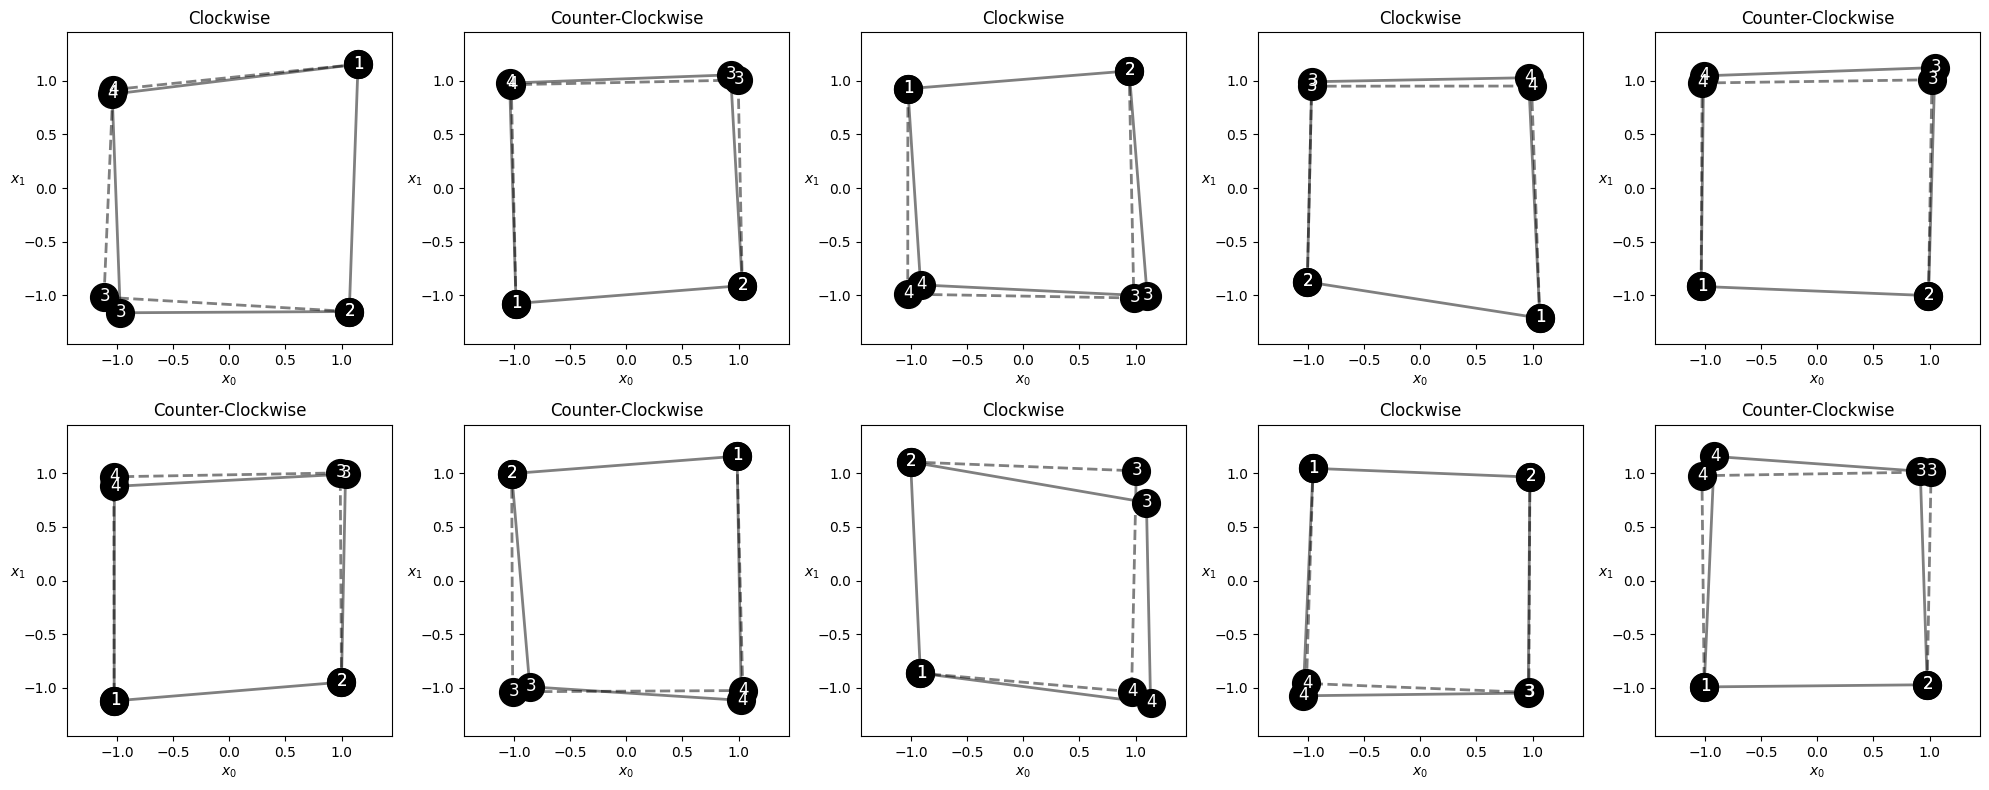

In [25]:
full_test = torch.as_tensor(test_points).float()
test_directions = torch.as_tensor(test_directions).long()
fig = sequence_pred(model, full_test, directions=test_directions)